Q1: Basic Statistics
                              count     mean      std     min      25%      50%      75%      max
class                         178.0    1.938    0.775    1.00    1.000    2.000    3.000     3.00
Alcohol                       178.0   13.001    0.812   11.03   12.362   13.050   13.678    14.83
Malic acid                    178.0    2.336    1.117    0.74    1.602    1.865    3.082     5.80
Ash                           178.0    2.367    0.274    1.36    2.210    2.360    2.558     3.23
Alcalinity of ash             178.0   19.495    3.340   10.60   17.200   19.500   21.500    30.00
Magnesium                     178.0   99.742   14.282   70.00   88.000   98.000  107.000   162.00
Total phenols                 178.0    2.295    0.626    0.98    1.742    2.355    2.800     3.88
Flavanoids                    178.0    2.029    0.999    0.34    1.205    2.135    2.875     5.08
Nonflavanoid phenols          178.0    0.362    0.124    0.13    0.270    0.340    0.438     0.66

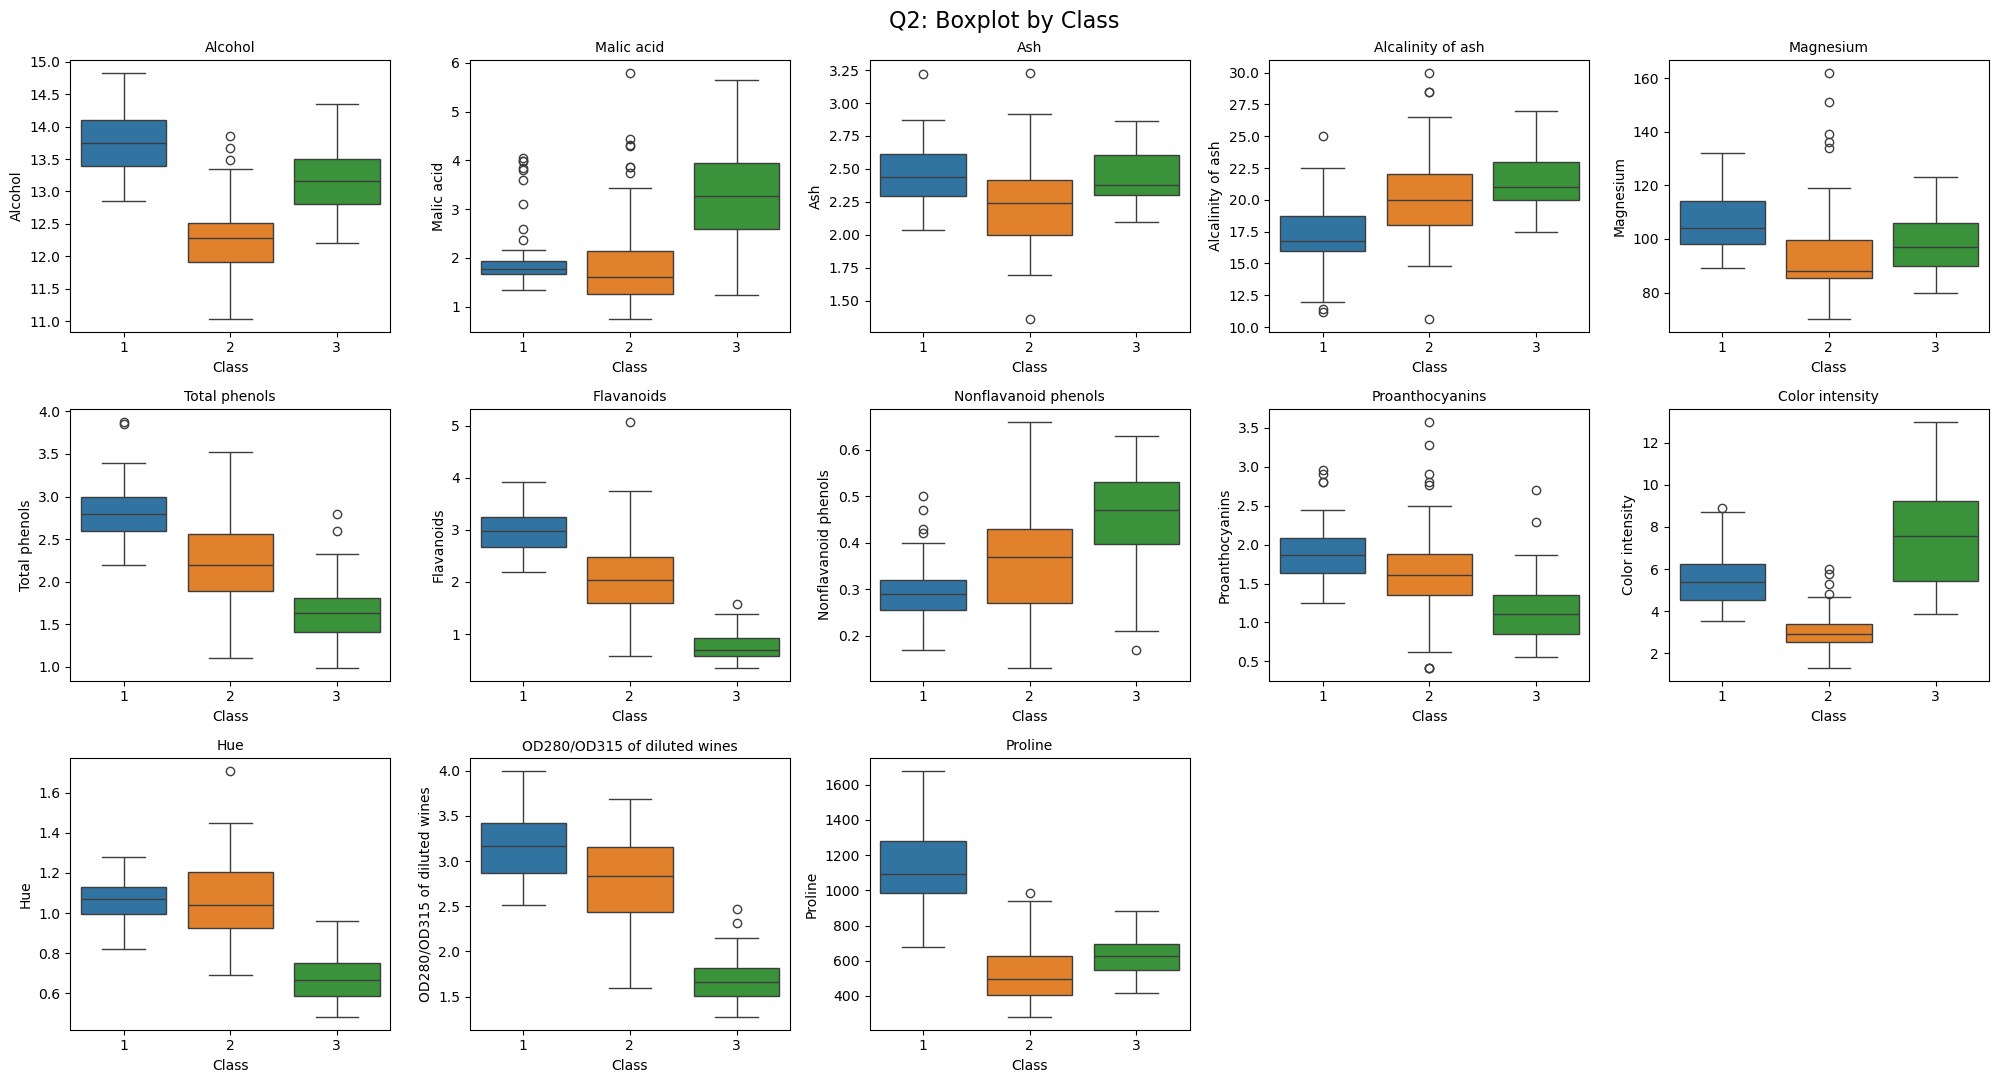

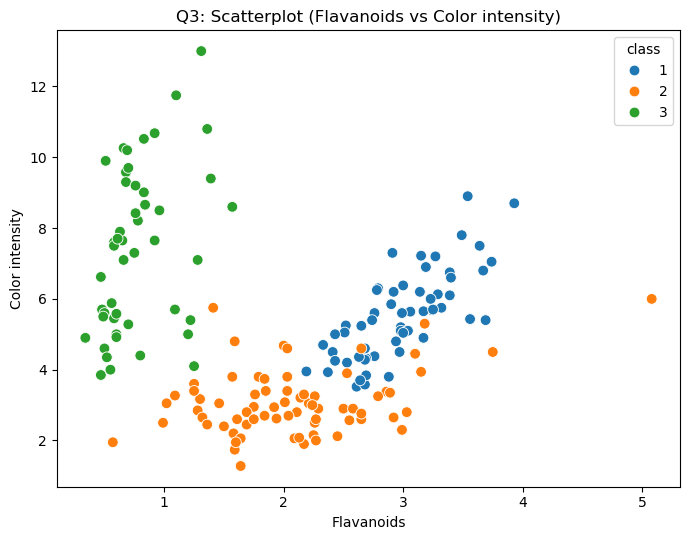

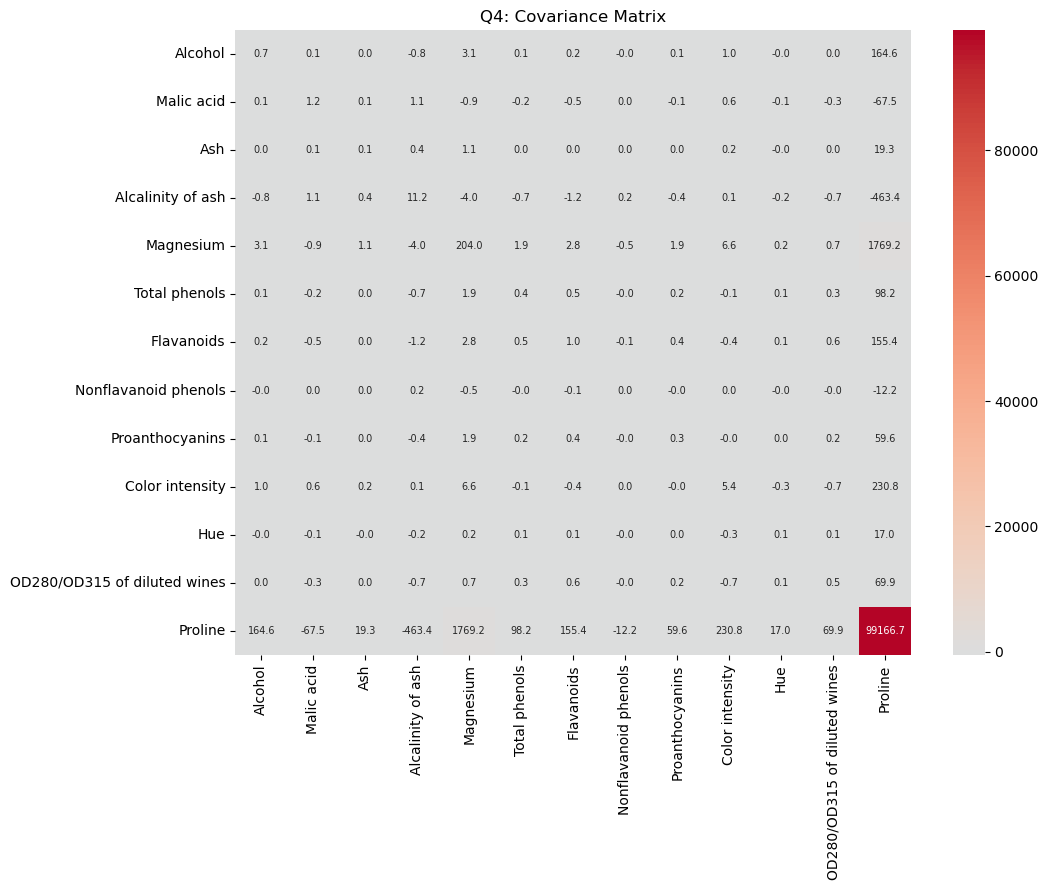


Q5: Data Scaling
                              mean    std
Alcohol                       -0.0  1.003
Malic acid                    -0.0  1.003
Ash                           -0.0  1.003
Alcalinity of ash             -0.0  1.003
Magnesium                     -0.0  1.003
Total phenols                  0.0  1.003
Flavanoids                    -0.0  1.003
Nonflavanoid phenols           0.0  1.003
Proanthocyanins               -0.0  1.003
Color intensity                0.0  1.003
Hue                            0.0  1.003
OD280/OD315 of diluted wines   0.0  1.003
Proline                       -0.0  1.003


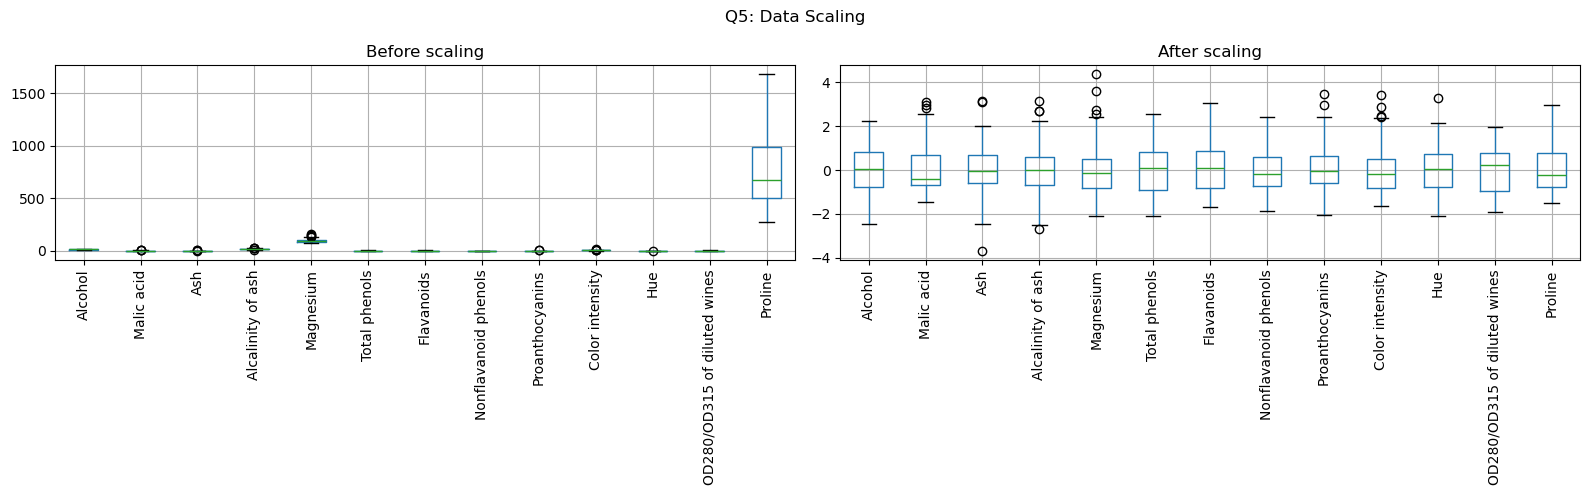

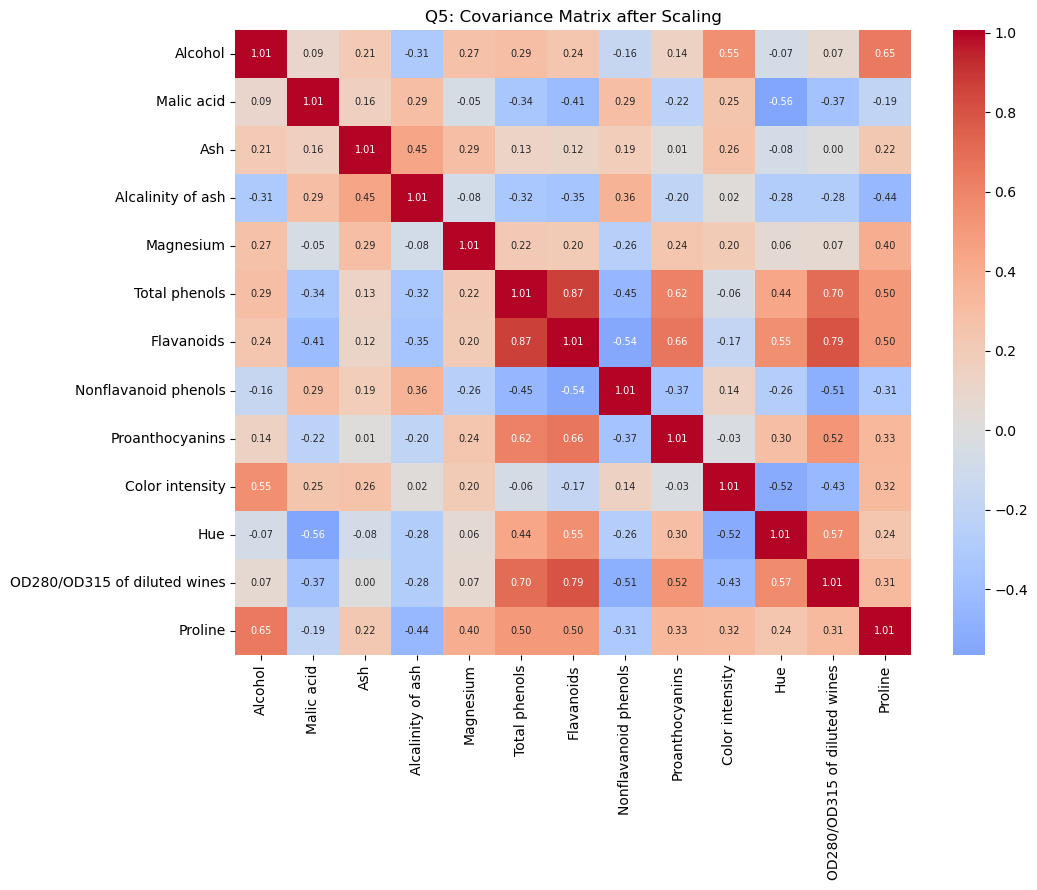


Q6: Class Separation using PCA
Explained variance ratio: [0.362 0.192]
Total explained variance: 0.554


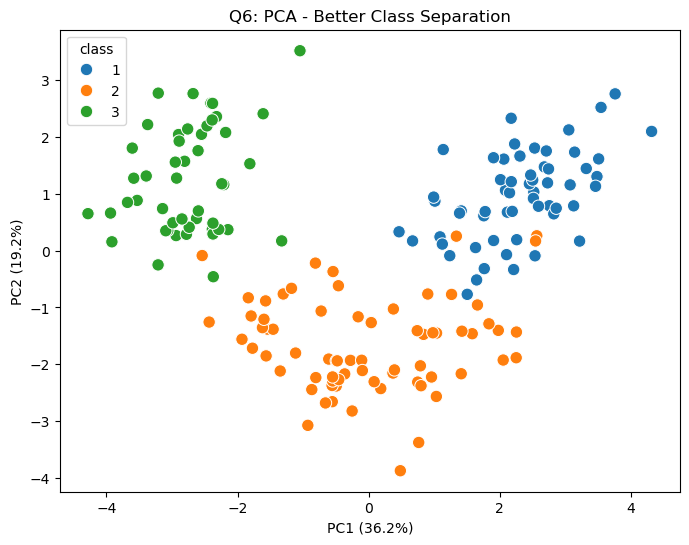

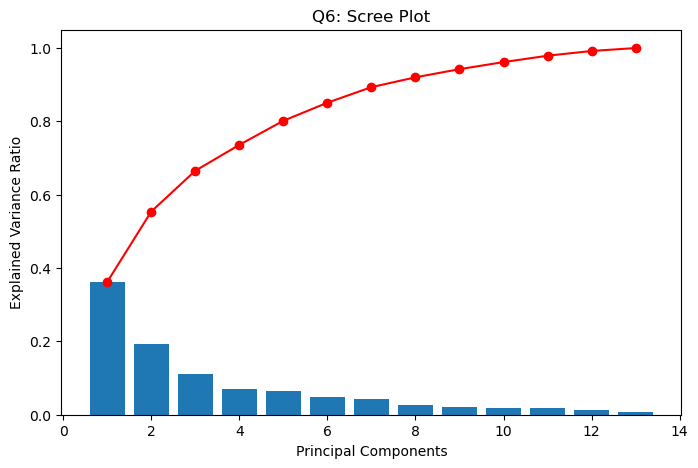

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("C:/Users/Ajsha/Downloads/archive (1)/Wine dataset.csv")
df.columns = df.columns.str.strip()
target = "class"
features = [c for c in df.columns if c != target]
pal = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}

# Q1: Basic Statistics
print("Q1: Basic Statistics")
pd.set_option("display.width", 250, "display.max_columns", 30)
print(df.describe().T.round(3))
print("\nClass counts:")
print(df[target].value_counts().sort_index())

# Q2: Boxplot by Class
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x=target, y=col, hue=target, palette=pal, legend=False, ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel("Class")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
fig.suptitle("Q2: Boxplot by Class", fontsize=16)
plt.tight_layout(); plt.show()

# Q3: Scatterplot
plt.figure(figsize=(7, 5.5))
sns.scatterplot(data=df, x="Flavanoids", y="Color intensity", hue=target, palette=pal, s=60)
plt.title("Q3: Scatterplot (Flavanoids vs Color intensity)")
plt.tight_layout(); plt.show()

# Q4: Covariance Matrix
plt.figure(figsize=(11, 9))
sns.heatmap(df[features].cov(), annot=True, fmt=".1f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Q4: Covariance Matrix")
plt.tight_layout(); plt.show()

# Q5: Data Scaling
print("\nQ5: Data Scaling")
X = df[features].values
y = df[target].values
Xs = StandardScaler().fit_transform(X)
df_scaled = pd.DataFrame(Xs, columns=features)
print(df_scaled.describe().T[["mean", "std"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
df[features].boxplot(ax=ax[0], rot=90); ax[0].set_title("Before scaling")
df_scaled.boxplot(ax=ax[1], rot=90);    ax[1].set_title("After scaling")
fig.suptitle("Q5: Data Scaling")
plt.tight_layout(); plt.show()

plt.figure(figsize=(11, 9))
sns.heatmap(df_scaled.cov(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Q5: Covariance Matrix after Scaling")
plt.tight_layout(); plt.show()

# Q6: Class Separation using PCA
print("\nQ6: Class Separation using PCA")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["class"] = y

print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="class", palette=pal, s=80)
plt.title("Q6: PCA - Better Class Separation")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.show()

# Scree plot
evr = PCA().fit(Xs).explained_variance_ratio_
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(evr) + 1), evr)
plt.plot(range(1, len(evr) + 1), np.cumsum(evr), "ro-")
plt.title("Q6: Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.show()